In [1]:
import os, re, glob, math, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

warnings.filterwarnings("ignore")

ROOT = "/kaggle/input/competitions/csp-p-2-hidden-cards/kaggle_dataset"
TRAIN_DIR = os.path.join(ROOT, "train")
TEST_DIR = os.path.join(ROOT, "test")
TRAIN_LABELS = os.path.join(ROOT, "train_labels.csv")
SAMPLE_SUB = os.path.join(ROOT, "sample_submission.csv")

train_df = pd.read_csv(TRAIN_LABELS)
sample_df = pd.read_csv(SAMPLE_SUB)

train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.csv")))
test_files = sorted(glob.glob(os.path.join(TEST_DIR, "*.csv")))

train_map = dict(zip(train_df["filename"], train_df["text"]))
test_map = {os.path.basename(p): p for p in test_files}

print(len(train_files), len(test_files))
train_df.head()

10 100


,filename,text
0,train_0000.csv,XAJI0
1,train_0001.csv,Y6DPB
2,train_0002.csv,HSAHX
3,train_0003.csv,THV3A
4,train_0004.csv,3ZMF8


In [2]:
ALPH = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"

def fix_text(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9]", "", s)
    return s[:5]

def zscore(a):
    a = np.asarray(a, dtype=np.float32)
    return (a - a.mean()) / (a.std() + 1e-9)

def knn_idx(a, k):
    k = int(k)
    k = max(1, min(k, len(a) - 1))
    nn = NearestNeighbors(n_neighbors=k + 1, algorithm="kd_tree")
    nn.fit(a)
    return nn.kneighbors(return_distance=False)[:, 1:]

def point_prob(df, ks=(8, 16, 24)):
    n = len(df)
    if n < 5:
        return np.full(n, 0.5, dtype=np.float32), np.zeros(n, dtype=np.float32)

    xy = df[["x", "y"]].to_numpy(np.float32)
    ff = df[["f1", "f2", "f3"]].to_numpy(np.float32)

    xy = StandardScaler().fit_transform(xy)
    ff = StandardScaler().fit_transform(ff)

    sc = np.zeros(n, dtype=np.float32)

    for k in ks:
        k = min(k, n - 1)
        if k < 1:
            continue

        ix = knn_idx(xy, k)
        ife = knn_idx(ff, k)

        d1 = np.linalg.norm(ff[ix] - ff[:, None, :], axis=2).mean(axis=1)
        d2 = np.linalg.norm(xy[ife] - xy[:, None, :], axis=2).mean(axis=1)

        a = np.exp(-d1)
        b = np.exp(-d2)

        ov = np.empty(n, dtype=np.float32)
        for i in range(n):
            ov[i] = len(set(ix[i]).intersection(set(ife[i]))) / k

        sc += 0.45 * zscore(a) + 0.45 * zscore(b) + 0.10 * zscore(ov)

    sc /= max(len(ks), 1)

    if np.allclose(sc, sc[0]):
        p = np.full(n, 0.5, dtype=np.float32)
        return p, sc

    gmm = GaussianMixture(n_components=2, random_state=0)
    gmm.fit(sc.reshape(-1, 1))
    p = gmm.predict_proba(sc.reshape(-1, 1))[:, np.argmax(gmm.means_.ravel())]
    return p.astype(np.float32), sc.astype(np.float32)

In [3]:
def render_cloud(df, p, blur=1.1, power=2.0):
    H, W = 101, 401
    img = np.zeros((H, W), dtype=np.float32)

    x = np.rint(df["x"].to_numpy()).astype(int)
    y = np.rint(df["y"].to_numpy()).astype(int)

    x = np.clip(x, 0, W - 1)
    y = np.clip(100 - y, 0, H - 1)

    w = np.clip(p, 0, 1) ** power
    np.add.at(img, (y, x), w)

    if blur > 0:
        img = cv2.GaussianBlur(img, (0, 0), blur)

    m = img.max()
    if m > 0:
        img = img / m

    return img

def prep_for_ocr(img):
    x = (255 * (1 - img)).astype(np.uint8)
    x = cv2.GaussianBlur(x, (3, 3), 0)
    _, x = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8), iterations=1)
    x = cv2.resize(x, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)
    return x

In [4]:
def tesseract_read(img, psm):
    try:
        import pytesseract
        cfg = f'--oem 3 --psm {psm} -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'
        data = pytesseract.image_to_data(img, config=cfg, output_type=pytesseract.Output.DATAFRAME)
        if data is None or len(data) == 0:
            return "", -1.0
        data = data.dropna(subset=["text"])
        if len(data) == 0:
            return "", -1.0

        txt = "".join(data["text"].astype(str).tolist())
        conf = pd.to_numeric(data["conf"], errors="coerce")
        conf = conf[conf >= 0].mean()
        conf = float(conf) if pd.notna(conf) else -1.0
        return fix_text(txt), conf
    except Exception:
        return "", -1.0

def build_templates():
    fonts = [
        cv2.FONT_HERSHEY_SIMPLEX,
        cv2.FONT_HERSHEY_DUPLEX,
        cv2.FONT_HERSHEY_COMPLEX,
    ]
    out = {}
    for ch in ALPH:
        arr = []
        for f in fonts:
            for sc in [1.6, 1.9, 2.2]:
                for th in [2, 3]:
                    im = np.zeros((80, 80), dtype=np.uint8)
                    cv2.putText(im, ch, (5, 60), f, sc, 255, th, cv2.LINE_AA)
                    _, im = cv2.threshold(im, 0, 255, cv2.THRESH_BINARY)
                    arr.append(im)
        out[ch] = arr
    return out

TEMPLATES = build_templates()

def split_5(crop):
    w = crop.shape[1]
    cuts = np.linspace(0, w, 6).astype(int)
    return [crop[:, cuts[i]:cuts[i+1]] for i in range(5)]

def best_char(img):
    if img.size == 0:
        return ""
    img = cv2.resize(img, (80, 80), interpolation=cv2.INTER_CUBIC)
    img = (img > 0).astype(np.float32)

    best = ("", -1.0)
    for ch, lst in TEMPLATES.items():
        for t in lst:
            tt = (t > 0).astype(np.float32)
            s = (img * tt).sum() / (np.linalg.norm(img) * np.linalg.norm(tt) + 1e-9)
            if s > best[1]:
                best = (ch, s)
    return best[0]

def template_ocr(img):
    g = img.copy()
    if g.max() <= 1:
        g = (g * 255).astype(np.uint8)

    g = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    cnts, _ = cv2.findContours(g, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes = [cv2.boundingRect(c) for c in cnts if cv2.contourArea(c) > 20]
    if not boxes:
        return ""

    x0 = min(x for x, y, w, h in boxes)
    y0 = min(y for x, y, w, h in boxes)
    x1 = max(x + w for x, y, w, h in boxes)
    y1 = max(y + h for x, y, w, h in boxes)

    crop = g[y0:y1, x0:x1]
    crop = cv2.copyMakeBorder(crop, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=0)

    parts = split_5(crop)
    out = "".join(best_char(p) for p in parts)
    return fix_text(out)

def ocr_multi(canvas):
    base = prep_for_ocr(canvas)
    variants = []

    for inv in [False, True]:
        x = 255 - base if inv else base
        for b in [0.0, 0.8, 1.2]:
            y = x.copy()
            if b > 0:
                y = cv2.GaussianBlur(y, (0, 0), b)
            for th in [False, True]:
                z = y.copy()
                if th:
                    _, z = cv2.threshold(z, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
                z = cv2.resize(z, None, fx=1, fy=1, interpolation=cv2.INTER_CUBIC)
                variants.append(z)

    cand = []
    for v in variants:
        for psm in [7, 8, 13]:
            txt, conf = tesseract_read(v, psm)
            if txt:
                cand.append((txt, conf))

    if cand:
        cand.sort(key=lambda x: (len(x[0]) == 5, x[1], sum(c.isalnum() for c in x[0]), len(x[0])), reverse=True)
        best = fix_text(cand[0][0])
        if len(best) == 5:
            return best

    for v in variants:
        t = template_ocr(v)
        if len(t) == 5:
            return t

    if cand:
        return fix_text(cand[0][0])
    return ""

In [5]:
def predict_file(path, ks=(8, 16, 24), blur=1.1, power=2.0):
    df = pd.read_csv(path)
    p, sc = point_prob(df, ks=ks)
    canvas = render_cloud(df, p, blur=blur, power=power)
    canvas=cv2.flip(canvas,0)
    txt = ocr_multi(canvas)
    return txt, canvas, p, sc

In [6]:
import re
import cv2
import numpy as np

def ocr_split(canvas):
    try:
        import pytesseract
    except:
        return ""

    img = (255 * (1 - canvas)).astype(np.uint8)
    img = cv2.GaussianBlur(img, (3,3), 0)
    _, img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    h, w = img.shape
    res = ""

    for i in range(5):
        x0 = int(i * w / 5)
        x1 = int((i+1) * w / 5)

        crop = img[:, x0:x1]

        ys, xs = np.where(crop > 0)
        if len(xs) == 0:
            res += "?"
            continue

        crop = crop[min(ys):max(ys)+1, min(xs):max(xs)+1]
        crop = cv2.copyMakeBorder(crop, 10,10,10,10, cv2.BORDER_CONSTANT, value=0)
        crop = cv2.resize(crop, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)

        cfg = '--psm 10 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'
        txt = pytesseract.image_to_string(crop, config=cfg)

        txt = re.sub(r'[^A-Z0-9]', '', txt.upper())
        res += txt[:1] if txt else "?"

    return res

In [7]:
grid = [
    ((6, 12, 18), 0.9, 2.0),
    ((8, 16, 24), 1.1, 2.0),
    ((10, 20, 30), 1.1, 2.0),
    ((8, 16, 24), 1.4, 2.0),
    ((12, 18, 24), 1.1, 1.8),
]

best = None
res = []

for ks, blur, power in grid:
    pred = []
    truth = []
    for _, r in tqdm(train_df.iterrows(), total=len(train_df), desc=f"ks={ks}, blur={blur}, power={power}"):
        fn = os.path.join(TRAIN_DIR, r["filename"])
        t, _, _, _ = predict_file(fn, ks=ks, blur=blur, power=power)
        pred.append(t)
        truth.append(r["text"])
    acc = np.mean([a == b for a, b in zip(pred, truth)])
    res.append((acc, ks, blur, power, pred))
    print("ACC:", acc, "KS:", ks, "BLUR:", blur, "POWER:", power)
    print(list(zip(truth, pred)))

best = max(res, key=lambda x: x[0])
print("BEST =", best[0], best[1], best[2], best[3])

ks=(6, 12, 18), blur=0.9, power=2.0: 100%|██████████| 10/10 [01:22<00:00,  8.30s/it]


ACC: 0.4 KS: (6, 12, 18) BLUR: 0.9 POWER: 2.0
[('XAJI0', 'XAJIO'), ('Y6DPB', 'YEDP3'), ('HSAHX', 'HSAHX'), ('THV3A', 'THV3A'), ('3ZMF8', 'SZMF8'), ('MDD4V', 'MDD4V'), ('30T9N', '30TIN'), ('T3W5U', 'T3W3U'), ('ZBIKC', 'ZBIKC'), ('IDKWN', 'IDKVV')]


ks=(8, 16, 24), blur=1.1, power=2.0: 100%|██████████| 10/10 [01:26<00:00,  8.63s/it]


ACC: 0.5 KS: (8, 16, 24) BLUR: 1.1 POWER: 2.0
[('XAJI0', 'KAJIO'), ('Y6DPB', 'YEDPB'), ('HSAHX', 'HSAHX'), ('THV3A', 'THV3A'), ('3ZMF8', 'SZMF8'), ('MDD4V', 'MDD4V'), ('30T9N', '30TON'), ('T3W5U', 'T3WSU'), ('ZBIKC', 'ZBIKC'), ('IDKWN', 'IDKWN')]


ks=(10, 20, 30), blur=1.1, power=2.0: 100%|██████████| 10/10 [01:34<00:00,  9.42s/it]


ACC: 0.6 KS: (10, 20, 30) BLUR: 1.1 POWER: 2.0
[('XAJI0', 'KAJIO'), ('Y6DPB', 'YEDPB'), ('HSAHX', 'HSAHX'), ('THV3A', 'THV3A'), ('3ZMF8', '3ZMF8'), ('MDD4V', 'MDD4V'), ('30T9N', '30TON'), ('T3W5U', 'T3W3U'), ('ZBIKC', 'ZBIKC'), ('IDKWN', 'IDKWN')]


ks=(8, 16, 24), blur=1.4, power=2.0: 100%|██████████| 10/10 [01:34<00:00,  9.50s/it]


ACC: 0.8 KS: (8, 16, 24) BLUR: 1.4 POWER: 2.0
[('XAJI0', 'XAJIO'), ('Y6DPB', 'Y6DPB'), ('HSAHX', 'HSAHX'), ('THV3A', 'THV3A'), ('3ZMF8', '3ZMF8'), ('MDD4V', 'MDD4V'), ('30T9N', '3OTON'), ('T3W5U', 'T3W5U'), ('ZBIKC', 'ZBIKC'), ('IDKWN', 'IDKWN')]


ks=(12, 18, 24), blur=1.1, power=1.8: 100%|██████████| 10/10 [01:41<00:00, 10.11s/it]

ACC: 0.6 KS: (12, 18, 24) BLUR: 1.1 POWER: 1.8
[('XAJI0', 'XAJIO'), ('Y6DPB', 'YEDPB'), ('HSAHX', 'HSAHX'), ('THV3A', 'THV3A'), ('3ZMF8', '3ZMF8'), ('MDD4V', 'MDD4V'), ('30T9N', '30TON'), ('T3W5U', 'T3W3U'), ('ZBIKC', 'ZBIKC'), ('IDKWN', 'IDKWN')]
BEST = 0.8 (8, 16, 24) 1.4 2.0


In [8]:
best_acc, best_ks, best_blur, best_power, _ = best

sub = sample_df.copy()
outs = []

for fn in tqdm(sub["filename"].tolist(), desc="Predict test"):
    path = test_map[fn]
    txt, _, _, _ = predict_file(path, ks=best_ks, blur=best_blur, power=best_power)
    outs.append(txt)

sub["text"] = outs
sub.to_csv("submission1.csv", index=False)
sub.head()

Predict test: 100%|██████████| 100/100 [15:55<00:00,  9.56s/it]


,filename,text
0,test_0000.csv,NHJ7X
1,test_0001.csv,GOFNS
2,test_0002.csv,UY411
3,test_0003.csv,LJH75
4,test_0004.csv,XO6QJ


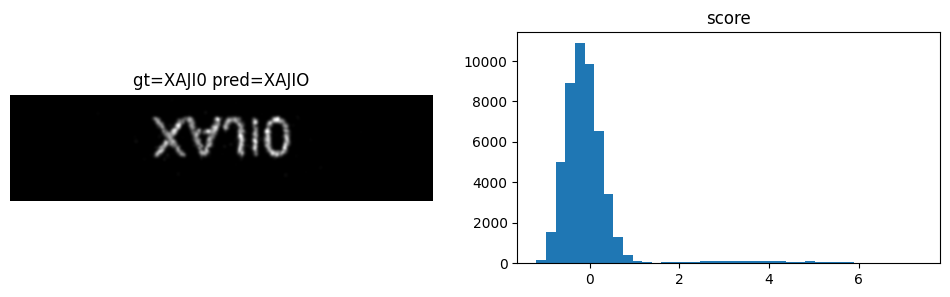

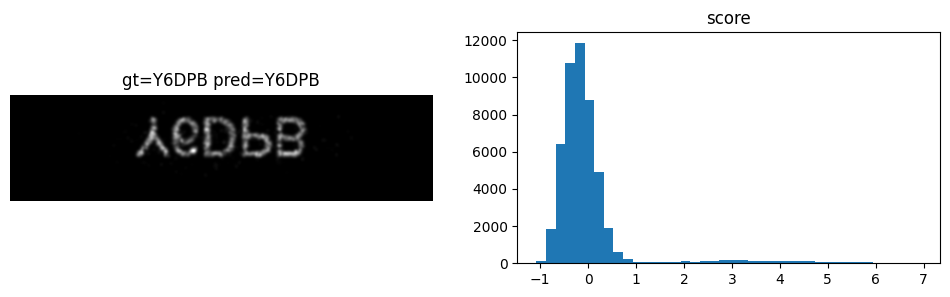

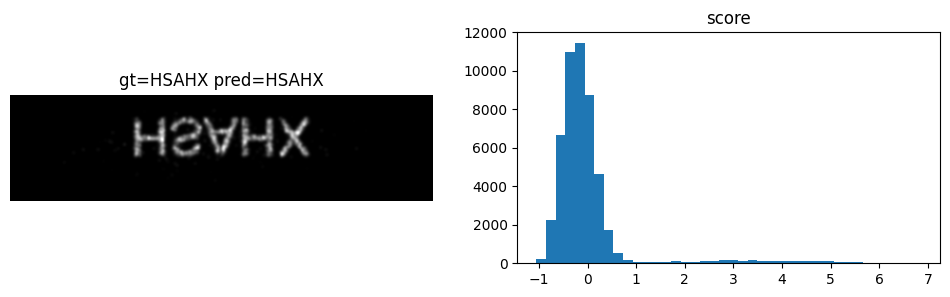

In [9]:
for i in range(min(3, len(train_df))):
    fn = os.path.join(TRAIN_DIR, train_df.iloc[i]["filename"])
    gt = train_df.iloc[i]["text"]
    pred, canvas, p, sc = predict_file(fn, ks=best_ks, blur=best_blur, power=best_power)
    canvas=cv2.flip(canvas,0)
    plt.figure(figsize=(12, 3))
    plt.subplot(1, 2, 1)
    plt.title(f"gt={gt} pred={pred}")
    plt.imshow(canvas, cmap="gray")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title("score")
    plt.hist(sc, bins=40)
    plt.show()